# Lo que una red ve de un holograma

**Pregunta:** ¿Qué entra a la red publicada y qué sale de ella, para un objetivo de tres planos, y con qué puntaje se la evalúa?

- **Nivel:** 1, Fundamentos
- **Requisitos previos:** notebooks 01 y 02 del tema 01-fourier-optics (el campo focal y las métricas de las trampas)
- **Tiempo de lectura:** unos 35 minutos; el notebook se ejecuta en unos 15 segundos

## Objetivos

Un holograma aprendido es un archivo: una red neuronal guardada como un grafo ONNX que recibe una imagen y devuelve una máscara de fase. Antes de preguntar si es buena, hay que saber exactamente qué se le da al grafo, qué devuelve y cómo su salida se vuelve a convertir en luz. Este notebook lleva un objetivo por la red publicada del producto, `cgh-net`: doce trampas en tres profundidades. Leerá lo que promete la ficha del grafo, construirá la entrada de la red a partir de las trampas, ejecutará el grafo con onnxruntime, reconstruirá a mano las imágenes que la fase hace en cada profundidad y la exactitud con que se evalúa a la red, y pondrá ese número junto a dos hologramas que no saben nada del objetivo. Al final podrá decir qué significa un número como 0.73 y qué no significa.

## Preparación

El entorno de los notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows). Los paquetes que usa este notebook, con sus versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2 onnxruntime==1.31.1
```

DinHot no publica un paquete propio: sus métodos viven en `data-pipeline/pipeline/` y el notebook los importa por su ruta. La red es el grafo ONNX publicado del producto, el mismo archivo que corre el navegador, leído con onnxruntime. La celda siguiente importa las herramientas, imprime sus versiones y pone el pipeline en la ruta.

In [1]:
# las herramientas y sus versiones, y luego los módulos del pipeline por su ruta
import importlib.metadata as md
import json
import sys
import warnings
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import onnxruntime as ort

warnings.filterwarnings("ignore")
ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases.build import setup_of
from pipeline.io.contract import read_cases
from pipeline.model.holo.core import forward, modes
from pipeline.model.holo.core.geometry import focal_bin_m
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.traps import Trap, TrapSet
from pipeline.model.holo.core.types import Budget, Target
from pipeline.model.holo.learned import convert, evaluation
from pipeline.model.holo.methods.learned import m17_cgh_net

for name in ("numpy", "matplotlib", "onnxruntime"):
    print(name, md.version(name))

numpy 2.4.6
matplotlib 3.11.2
onnxruntime 1.31.1


## Datos

- Propietario: este repositorio, https://github.com/fsantibanezleal/CEFOP_DinHot.
- Clase de licencia: sintética. El caso lo escribe el producto y la red se entrenó con objetivos sorteados por un generador con semilla, de modo que no interviene ningún conjunto de datos de terceros y la licencia del repositorio cubre todos los archivos.
- Archivos leídos: `data/examples/cases.json` (caso C05, la óptica a 1064 nm y la red de sitios), el grafo publicado `models/cgh-net.onnx` y su ficha `models/cgh-net.json`.

El caso C05 se escribió para un modulador espacial de luz (SLM) de 256 por 256 píxeles, y la red se entrenó para 128 por 128 píxeles sin relleno. La celda siguiente conserva la óptica del caso (1064 nm, 2.4 mm de distancia focal, píxeles de 10 um) y fija la malla a la de la red, y luego imprime lo que la ficha dice que el grafo recibe y devuelve.

In [2]:
# el caso C05 da la óptica y la red de sitios; la ficha del grafo publicado dice para qué se construyó la red
records = {rec["case_id"]: rec for rec in read_cases(ROOT / "data" / "examples" / "cases.json")}
rec = records["C05_multiplane_vortices"]
setup = replace(setup_of(rec), n_pix=128, pad=1)
card = json.loads((ROOT / "models" / "cgh-net.json").read_text(encoding="utf-8"))
bin_m, zr = focal_bin_m(setup), convert.rayleigh_range_m(setup)
print(f"ficha: ranura {card['slot']}, opset {card['opset']}, {card['bytes'] / 1e6:.2f} MB, malla {card['grid']}")
port_in, port_out = card["inputs"][0], card["outputs"][0]
print(f"entrada de la ficha: {port_in['name']} {port_in['shape']}")
print(f"salida de la ficha: {port_out['name']} {port_out['shape']}")
print(f"un bin focal = {bin_m * 1e6:.3f} um, un rango de Rayleigh de la apertura = {zr * 1e6:.2f} um")

ficha: ranura cgh-net, opset 17, 4.67 MB, malla 128
entrada de la ficha: target [1, 3, 128, 128]
salida de la ficha: phase [1, 1, 128, 128]
un bin focal = 1.995 um, un rango de Rayleigh de la apertura = 4.76 um


La ficha declara el contrato. El grafo recibe un arreglo de forma 1 por 3 por 128 por 128, tres imágenes de 128 por 128 bins, y devuelve un arreglo de forma 1 por 1 por 128 por 128, una fase para un SLM de 128 por 128. Un bin focal mide 1.995 um en esta óptica, y la unidad de profundidad es el rango de Rayleigh de la apertura del SLM, 4.76 um.

## Método

**El objetivo.** La red se construyó siguiendo a DeepCGH (Eybposh et al. 2020, https://doi.org/10.1364/OE.399624): una red convolucional lleva la intensidad deseada en varios planos a una fase para el SLM. En la versión del producto, M17, los planos están en $z = -8$, $0$ y $+8$ rangos de Rayleigh $z_R = \lambda f^2 / (\pi R^2)$ de la apertura de radio $R = N p/2$, las trampas están en bins focales enteros a no más de 60 bins del eje, los objetivos con que se entrenó tienen el mismo número de trampas en cada plano y ninguna lleva carga de vórtice. Cada trampa se dibuja como un punto gaussiano de un bin de ancho, y la imagen de cada plano se escala a energía unitaria.

**El puntaje.** Con $T_p$ la imagen objetivo del plano $p$ e $I_p$ la intensidad que el holograma hace allí, ambas con suma unitaria, la exactitud es $AC = \frac{1}{3}\sum_p 2\sum T_p I_p / (\sum T_p^2 + \sum I_p^2)$. Vale 1 cuando las dos imágenes son idénticas y cae hacia 0 cuando dejan de traslaparse. El producto usa esta lectura de la medida de DeepCGH para la pérdida de entrenamiento, las líneas base y la evaluación por igual; la fórmula propia del artículo no se abrió para este notebook, de modo que esa coincidencia queda SIN VERIFICAR. La imagen de plano de una fase $\phi$ es $I_p = |\mathcal{F}\{A\,e^{i(\phi - \phi_{z_p})}\}|^2$, donde $\phi_{z_p}$ es el término de lente que enfoca el SLM a la profundidad $z_p$.

El primer paso construye el objetivo. La celda toma doce sitios de la red del caso y pone cada uno en una sola profundidad, cuatro en cada uno de los tres planos, de modo que los planos difieran y ningún sitio se repita.

In [3]:
# doce sitios de la red de C05, cada uno en una sola profundidad: cuatro por plano en -8, 0 y +8 rangos
sites = [t for t in rec["target"]["traps"] if t["charge"] == 0 and t["z_um"] == 0.0][:12]
placed = []
for k, t in enumerate(sites):
    x_bin, y_bin = round(t["x_um"] * 1e-6 / bin_m), round(t["y_um"] * 1e-6 / bin_m)
    placed.append(Trap(k, x_bin * bin_m, y_bin * bin_m, (k % 3 - 1) * 8 * zr))
target = Target.from_traps(TrapSet(placed))
depth = np.rint(target.traps.z_m / (8 * zr)).astype(int)
print("trampas por plano (-8, 0, +8 rangos):", np.bincount(depth + 1).tolist())
print("posiciones laterales (bins):", [(round(t.x_m / bin_m), round(t.y_m / bin_m)) for t in placed[:3]], "...")

trampas por plano (-8, 0, +8 rangos): [4, 4, 4]
posiciones laterales (bins): [(4, 0), (2, 3), (-4, 0)] ...


Cuatro trampas por plano, como espera la red. El paso siguiente las convierte en su entrada con la función propia del producto. La salida es un arreglo de 1 por 3 por 128 por 128 números de tipo float32, cada plano tiene energía 1.0, y solo 577 de los 49152 valores superan el uno por ciento de la mayor amplitud, 0.1995. La entrada son sobre todo ceros con doce pequeños puntos brillantes, que es lo que la red ve: ni fases ni holograma, solo dónde debe estar la luz y a qué profundidad.

In [4]:
# la entrada de la red: una imagen de amplitud por plano, cada una con energía unitaria
amps = m17_cgh_net.planes_from_traps(setup, target.traps)
print("arreglo de entrada:", amps.shape, amps.dtype)
print("energía por plano:", (amps.astype(float) ** 2).sum(axis=(2, 3)).round(3).tolist()[0])
lit = int((amps > 0.01 * amps.max()).sum())
print(f"mayor amplitud {amps.max():.4f}, bins sobre el 1 % de ella: {lit} de {amps.size}")

arreglo de entrada: (1, 3, 128, 128) float32
energía por plano: [1.0, 1.0, 1.0]
mayor amplitud 0.1995, bins sobre el 1 % de ella: 577 de 49152


La figura dibuja la amplitud al cuadrado, la intensidad que se le pide a la red, en una ventana de 80 por 80 bins alrededor del eje en cada una de las tres profundidades.

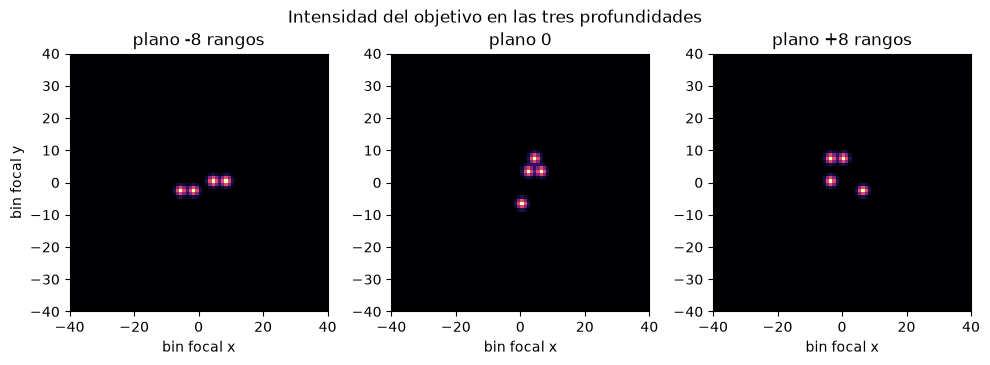

In [5]:
# los tres planos del objetivo como la intensidad que se le pide a la red
DEPTHS = ("plano -8 rangos", "plano 0", "plano +8 rangos")
fig, axes = plt.subplots(1, 3, figsize=(10, 3.5))
for ax, image, name in zip(axes, amps[0], DEPTHS):
    ax.imshow(image[24:104, 24:104] ** 2, cmap="magma", origin="lower", extent=(-40, 40, -40, 40))
    ax.set_title(name)
    ax.set_xlabel("bin focal x")
axes[0].set_ylabel("bin focal y")
fig.suptitle("Intensidad del objetivo en las tres profundidades")
fig.tight_layout()
plt.show()

Cada panel tiene cuatro puntos de unos dos bins de ancho, y ningún par de paneles comparte una posición, de modo que los tres planos son patrones distintos. Lo que se le da a la red es entonces una pila de tres imágenes, no una lista de coordenadas: no tiene noción de trampa, solo de píxeles brillantes. La figura no muestra la profundidad como un número, porque la profundidad es la posición de la imagen en la pila, primera, segunda o tercera. Una profundidad distinta de las tres del entrenamiento no tendría cómo pedirse, y por eso el método del producto rechaza objetivos que no estén en esos tres planos. El paso siguiente da esta entrada al grafo.

El segundo paso ejecuta el grafo. La celda abre el archivo ONNX con onnxruntime en la CPU, imprime el nombre, la forma y el tipo de cada puerto que el propio archivo declara y llama a `predict` del producto sobre la entrada. Como comprobación de la forma en que el producto envuelve el archivo, llama también al método completo con su refinamiento apagado y compara la fase.

In [6]:
# el grafo publicado a través de onnxruntime: lo que declara la sesión y la fase que devuelve para esta entrada
session = ort.InferenceSession(str(ROOT / "models" / "cgh-net.onnx"), providers=["CPUExecutionProvider"])
for port in session.get_inputs() + session.get_outputs():
    print(port.name, port.shape, port.type)
phase = m17_cgh_net.predict(session, amps)
print("máscara de fase:", phase.shape, phase.dtype, f"rango {phase.min():.3f} a {phase.max():.3f} rad")
whole = m17_cgh_net.run(setup, target, budget=Budget(1), rng=Rng(1), refine=False)
print("el método con el refinamiento apagado devuelve la misma fase:", bool(np.allclose(whole.phi, phase, atol=1e-5)))

target [1, 3, 128, 128] tensor(float)
phase [1, 1, 128, 128] tensor(float)
máscara de fase: (128, 128) float64 rango -3.141 a 3.141 rad
el método con el refinamiento apagado devuelve la misma fase: True


El archivo declara los mismos dos puertos que la ficha, la entrada `target` y la salida `phase`, y la fase es un arreglo de 128 por 128 que va de -3.141 a 3.141 rad, de modo que está envuelta a una vuelta. El método completo con el refinamiento apagado devuelve la misma fase, así que una pasada del grafo es todo lo que hace `cgh-net` en este modo. La fase es una sola máscara para los tres planos: la red tiene que encontrar un único patrón que, enfocado a tres profundidades distintas, haga tres imágenes distintas.

El tercer paso reconstruye el puntaje a mano. La celda define la imagen de una fase a una profundidad, reenfocando con el término de lente del motor y tomando la FFT focal del motor, escala las imágenes objetivo a suma unitaria y aplica la fórmula de la sección Método a cada plano. Imprime los tres valores y su media junto a `plane_accuracy` del propio producto.

In [7]:
# el holograma en cada profundidad: reenfocar con el término de lente del plano, FFT focal, suma unitaria
images = []
for ranges in (-8, 0, 8):
    field = forward.fft_focal_field(phase - modes.lens_phase(setup, ranges * zr), setup)
    intensity = np.abs(field) ** 2
    images.append(intensity / intensity.sum())
wanted = [(a.astype(float) ** 2) / np.sum(a.astype(float) ** 2) for a in amps[0]]
by_hand = [2 * np.sum(w * i) / (np.sum(w**2) + np.sum(i**2)) for w, i in zip(wanted, images)]
print("exactitud por plano a mano:", np.round(by_hand, 4).tolist(), "media", round(float(np.mean(by_hand)), 4))
print("la función propia del producto:", round(evaluation.plane_accuracy(amps[0], phase, setup), 4))

exactitud por plano a mano: [0.8276, 0.5724, 0.7859] media 0.7286
la función propia del producto: 0.7286


La exactitud es 0.8276 en el plano de -8, 0.5724 en el plano central y 0.7859 en el plano de +8, y su media, 0.7286, es el número que devuelve la función del producto, de modo que la definición a mano es la del producto. El plano central es el más débil por un margen amplio. Este notebook tiene un objetivo y una red, de modo que no puede decir si el plano central es sistemáticamente más difícil o si los cuatro puntos de ese plano son un conjunto incómodo; solo informa lo que se mide.

El cuarto paso da una escala al número. Un puntaje de 0.73 significa poco hasta que se lo pone junto a hologramas que no miraron el objetivo. La celda evalúa la red, un SLM sin modular (una fase plana) y una fase aleatoria, con la misma función, y luego el puntaje de un plano idéntico a su objetivo, que es el techo de la escala.

In [8]:
# tres hologramas por el mismo evaluador: la red, un SLM sin modular y una fase aleatoria
random_phase = np.random.default_rng(7).uniform(-np.pi, np.pi, phase.shape)
candidates = {"cgh-net": phase, "fase plana": np.zeros_like(phase), "fase aleatoria": random_phase}
scores = {name: evaluation.plane_accuracy(amps[0], phi, setup) for name, phi in candidates.items()}
for name, value in scores.items():
    print(f"{name:12s} exactitud {value:.4f}  pérdida {1 - value:.4f}")
perfect = np.mean([2 * np.sum(w * w) / (np.sum(w**2) + np.sum(w**2)) for w in wanted])
print(f"un plano idéntico a su objetivo obtiene {perfect:.4f}")

cgh-net      exactitud 0.7286  pérdida 0.2714
fase plana   exactitud 0.1196  pérdida 0.8804
fase aleatoria exactitud 0.0068  pérdida 0.9932
un plano idéntico a su objetivo obtiene 1.0000


La red obtiene 0.7286, la fase plana 0.1196 y la fase aleatoria 0.0068, y un plano idéntico al objetivo obtiene 1.0000. La pérdida, uno menos la exactitud, es 0.2714, 0.8804 y 0.9932. Una fase aleatoria dispersa la luz en moteado y deja casi nada sobre el objetivo, y una fase plana hace el mismo patrón sea cual sea el objetivo. La figura muestra la máscara de la red a la izquierda y, en los tres paneles de su derecha, la intensidad que esa máscara hace en cada profundidad con los doce sitios del objetivo marcados en cian, en escala de raíz cuadrada para que se vea la luz entre los puntos.

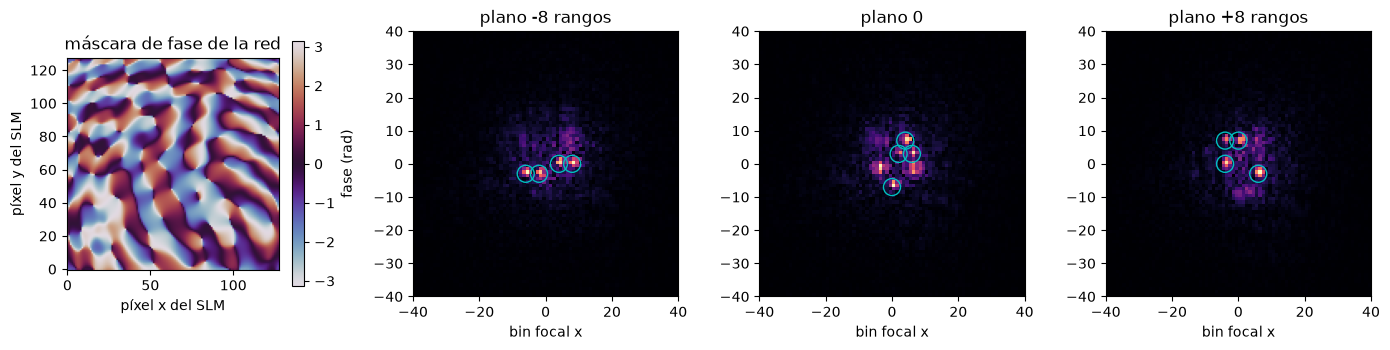

In [9]:
# la máscara de fase y la intensidad que hace en las tres profundidades, con los sitios marcados
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6))
mask = axes[0].imshow(phase, cmap="twilight", vmin=-np.pi, vmax=np.pi, origin="lower")
axes[0].set_title("máscara de fase de la red")
axes[0].set_xlabel("píxel x del SLM")
axes[0].set_ylabel("píxel y del SLM")
fig.colorbar(mask, ax=axes[0], label="fase (rad)", shrink=0.8)
for ax, ranges, image, name in zip(axes[1:], (-8, 0, 8), images, DEPTHS):
    ax.imshow(np.sqrt(image[24:104, 24:104]), cmap="magma", origin="lower", extent=(-40, 40, -40, 40))
    here = target.traps.z_m == ranges * zr
    ax.scatter(target.traps.x_m[here] / bin_m, target.traps.y_m[here] / bin_m, s=150, facecolors="none", edgecolors="c")
    ax.set_title(name)
    ax.set_xlabel("bin focal x")
fig.tight_layout()
plt.show()

La máscara es un patrón suave y arremolinado con una textura de franjas y ningún parecido con ninguna de las tres imágenes, que es como se ve un holograma de fase: la información está en la relación de Fourier, no en la apariencia de la máscara. En cada profundidad los puntos brillantes caen dentro o junto a los círculos cian, y cada plano lleva además una bruma difusa de moteado, en parte presumiblemente la luz hecha para las otras dos profundidades, desenfocada; la figura no puede separar las dos. La bruma cuesta exactitud, porque el puntaje cuenta cada bin y el objetivo está casi vacío. La figura no muestra la intensidad de cada trampa frente a las otras, de modo que no puede decir si los doce puntos son iguales; la exactitud tampoco puede decirlo.

La última figura pone los cuatro puntajes lado a lado como barras: los tres hologramas y el techo de la escala.

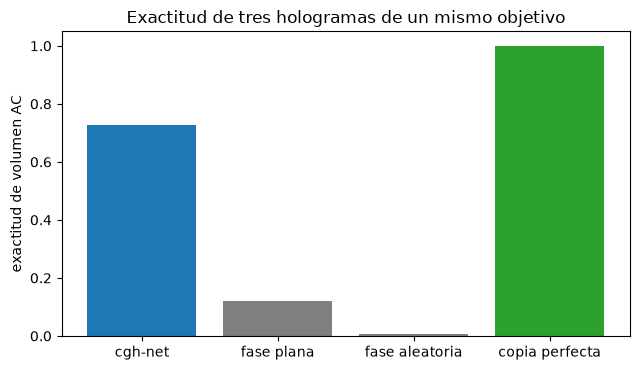

In [10]:
# la exactitud de los tres hologramas y la de una copia perfecta del objetivo, como barras
fig, ax = plt.subplots(figsize=(6.5, 3.8))
names = list(scores) + ["copia perfecta"]
ax.bar(names, list(scores.values()) + [perfect], color=["C0", "C7", "C7", "C2"])
ax.set_ylabel("exactitud de volumen AC")
ax.set_title("Exactitud de tres hologramas de un mismo objetivo")
fig.tight_layout()
plt.show()

La barra de la red está a unos siete décimos del camino entre la fase plana y la copia perfecta, y las barras de la fase plana y la aleatoria apenas se ven: un holograma informado y uno no informado están muy separados en esta escala, de modo que la métrica los distingue bien. No mide cuán cerca está la red de la mejor máscara de fase que existe, porque nadie conoce esa máscara, y un puntaje de 0.73 no es bueno ni malo por sí solo. Que sea bueno es una comparación con el lazo clásico al mismo costo, y ese es el trabajo de los notebooks siguientes de este tema.

## Resultados

**Respuesta:** La red recibe una pila de tres imágenes de amplitud de energía unitaria, una por profundidad en -8, 0 y +8 rangos de Rayleigh, de 128 por 128 bins cada una, 1 por 3 por 128 por 128 números float32 de los cuales solo 577 de 49152 superan el uno por ciento del máximo, y devuelve una fase de 128 por 128 envuelta entre -3.141 y 3.141 rad. Se la evalúa con la exactitud, la media sobre los tres planos de un traslape normalizado entre el objetivo y la intensidad que la fase hace allí: 0.8276, 0.5724 y 0.7859 en los planos de este objetivo de doce trampas, 0.7286 en promedio, que la función propia del producto reproduce. En la misma escala una fase plana obtiene 0.1196, una fase aleatoria 0.0068 y una copia perfecta 1.0000. El notebook muestra un objetivo y una red, de modo que no dice cómo varía el puntaje entre objetivos, si las trampas salen iguales ni si el lazo clásico lo hace mejor al mismo costo.

## Resumen

`cgh-net` es una función de tres imágenes a una máscara de fase, con la profundidad llevada por el orden de las imágenes y el objetivo fijo a tres planos, bins enteros y cantidades iguales. Su puntaje, la exactitud, compara imágenes completas y no las trampas, y pone una fase plana en 0.1196 y a la red en 0.7286 en este objetivo. El notebook siguiente pregunta cómo una red puede aprender una función así sin que nunca se le muestre un holograma correcto.

## Referencias

- Eybposh, Caira, Atisa, Chakravarthula and Pégard, "DeepCGH: 3D computer-generated holography using deep learning", Optics Express 28, 26636 (2020), https://doi.org/10.1364/OE.399624.
- onnxruntime 1.31.1 (MIT), https://pypi.org/pypi/onnxruntime/json and https://pypi.org/project/onnxruntime/.